# Classificatore quantistico delle galassie — Galaxy Zoo 2

In questo notebook prepariamo l'ambiente, carichiamo il dataset Galaxy Zoo 2, costruiamo e addestriamo un circuito quantistico e infine ne valutiamo le classificazioni.

## 1. Setup dell'ambiente

Installiamo Qiskit, il simulatore Aer e le librerie per gestire i dati, ottimizzare i parametri e valutare il classificatore.
Inoltre carichiamo manualmente, nella cartella "content" di Colab, il dataset per l'addestramento del classificatore

In [1]:
%pip install -q "numpy<2.5" matplotlib qiskit qiskit-aer qiskit-ibm-runtime scipy pandas scikit-learn pylatexenc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have py

## 2. Importiamo gli strumenti necessari

Importiamo le classi e le funzioni che useremo nei passaggi successivi.

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.executor_sampler import Sampler
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from IPython.display import display

Definiamo `run(qc, shots)`, che esegue un circuito sul simulatore Aer e restituisce i conteggi delle misurazioni.

In [3]:
def run(qc, shots=1024):
    sim_backend = AerSimulator()
    pm = generate_preset_pass_manager(backend=sim_backend)
    isa_qc = pm.run(qc)
    sampler = Sampler(mode=sim_backend)

    job = sampler.run([isa_qc], shots=shots)
    results = job.result()
    counts = results[0].data.c.get_counts()
    return counts

## 3. Carichiamo il dataset

Leggiamo il file CSV creato in precedenza, selezionando le quattro colonne da usare come input e separando le caratteristiche (`X`) dalle etichette (`y`).

In [4]:
df = pd.read_csv("/content/galaxy_zoo_quantum.csv")

features = [
    "edge_on_fraction",
    "bar_fraction",
    "prominent_bulge_fraction",
    "odd_feature_fraction"
]

X = df[features].to_numpy(dtype=float)
y = df["label"].to_numpy(dtype=int)

print("Dimensioni dataset:", X.shape)
print(df["class_name"].value_counts())
display(df)

Dimensioni dataset: (200, 4)
class_name
ellittica_smooth    100
spirale_disk        100
Name: count, dtype: int64


,dr7objid,ra,dec,edge_on_fraction,bar_fraction,prominent_bulge_fraction,odd_feature_fraction,label,class_name
0,587732135386677362,186.260880,52.325272,0.000000,0.000000,0.000000,0.095854,0,ellittica_smooth
1,587738618103660624,181.848190,38.442432,0.000000,0.000000,0.000000,0.233249,0,ellittica_smooth
2,587742061597884554,155.711395,19.918476,0.000000,1.000000,0.000000,0.106441,0,ellittica_smooth
3,587732577774141595,162.860580,6.622690,0.001181,0.344660,0.025781,0.328462,1,spirale_disk
4,587729159502823594,193.631653,5.165935,1.000000,0.000000,0.000000,0.375510,1,spirale_disk
...,...,...,...,...,...,...,...,...,...
195,588017991774175587,229.059036,7.443673,1.000000,0.000000,0.000000,0.215904,1,spirale_disk
196,587739408387211435,169.420914,34.922966,0.000000,0.000000,0.000000,0.094734,0,ellittica_smooth
197,588010360689852537,163.908203,5.786370,0.205008,0.000000,0.000000,0.140198,0,ellittica_smooth
198,588018055125205079,245.131317,32.243011,0.014026,0.636556,0.000000,0.135058,1,spirale_disk


## 4. Dividiamo i dati in training set e test set

Dividiamo le 200 galassie in un insieme per l'addestramento e uno per il test. La divisione mantiene la stessa proporzione tra galassie ellittiche e spirali.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Galassie per addestramento:", len(X_train))
print("Galassie per test:", len(X_test))

Galassie per addestramento: 150
Galassie per test: 50


## 5. Costruiamo il circuito quantistico

La cella seguente definisce il circuito a quattro qubit. Riceve le caratteristiche di una galassia, applica le porte di codifica e i blocchi di porte parametrizzate, quindi restituisce il circuito. Alla fine ne visualizza un esempio.

Definiamo i parametri iniziali del nostro circuito quantistico:

- N_QUBITS = Numero di qubit del circuito; ciascuno codifica una caratteristica della galassia.

- N_LAYERS = Numero di strati di operazioni quantistiche variabili.

- N_PARAMS_PER_QUBIT = Numero di parametri che ogni qubit possiede per ogni strato.

In [ ]:
N_QUBITS = 4
N_LAYERS = 2
N_PARAMS_PER_QUBIT = 2

Definiamo la funzione **galaxy_circuit** che riceve tre argomenti:

- **x** : contiene le 4 caratteristiche numeriche della galassia.

- **theta** : contiene i parametri variabili del circuito quantistico.

- **measure** : stabilisce se effettuare oppure no la misurazione dei qubit.

In [ ]:
def galaxy_circuit(x, theta, measure=False):
    # Se measure è True salviamo il risultato della misurazione in un bit classico
    qc = QuantumCircuit(N_QUBITS, 1 if measure else 0)

    # Codifica delle quattro caratteristiche
    for q in range(N_QUBITS):
        qc.ry(np.pi * x[q], q)

    qc.barrier(label="data")

    # Circuito variazionale (Machine Learning)
    for layer in range(N_LAYERS):
        for q in range(N_QUBITS):
            qc.ry(theta[layer, q, 0], q)
            qc.rz(theta[layer, q, 1], q)

        # Entanglement tra qubit adiacenti
        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

        qc.barrier(label=f"layer_{layer + 1}")

    if measure:
        qc.measure(0, 0)

    return qc

Visualizziamo la struttura del circuito appena realizzato

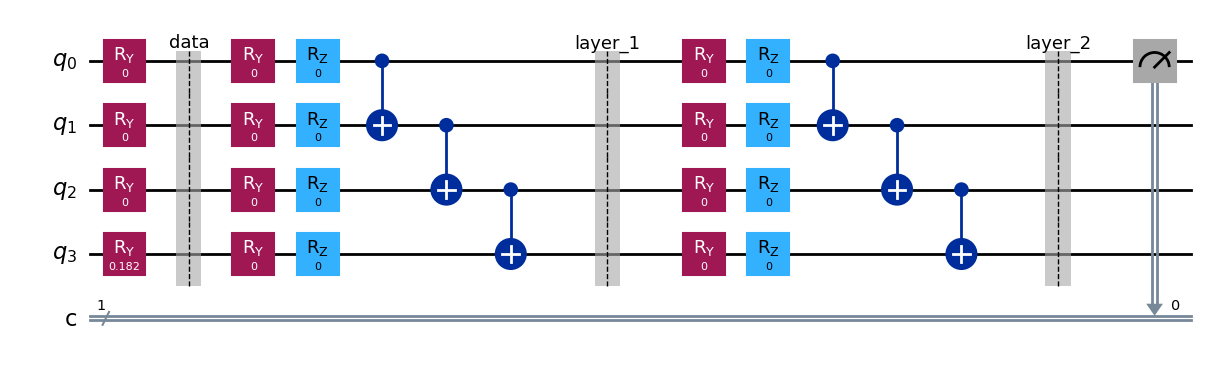

In [ ]:
# Disegniamo il circuito con parametri iniziali nulli
theta_0 = np.zeros((N_LAYERS, N_QUBITS, N_PARAMS_PER_QUBIT))
qc_example = galaxy_circuit(X_train[0], theta_0, True)
display(qc_example.draw("mpl"))

## 6. Definiamo l'osservabile e la funzione costo

Definiamo l'osservabile usato per leggere l'uscita del circuito e una funzione che trasforma tale uscita nella probabilità della classe spirale. Calcoliamo poi la funzione costo (Cost Function) confrontando le probabilità previste con le etichette note del training set.

In [ ]:
# Osservabile Z sul qubit 0 e identità sugli altri tre
Z_readout = SparsePauliOp("IIIZ")

def probability_spiral(x, theta):
    qc = galaxy_circuit(x, theta)
    # simula l'esecuzione del circuito qc e restituisce il suo stato quantistico finale
    state = Statevector.from_instruction(qc)
    expectation_z = state.expectation_value(Z_readout).real
    return float((1 - expectation_z) / 2)

def cost_function(parameters):
    theta = parameters.reshape(N_LAYERS, N_QUBITS, N_PARAMS_PER_QUBIT)

    probabilities = np.array([
        probability_spiral(x, theta) for x in X_train
    ])
    probabilities = np.clip(probabilities, 1e-8, 1 - 1e-8)

    # Binary cross-entropy: errore tra probabilità previste e label note
    cost = -np.mean(
        y_train * np.log(probabilities) + (1 - y_train) * np.log(1 - probabilities)
    )
    return cost

## 7. Addestriamo il circuito: ottimizzazione ibrida

Inizializziamo i parametri del circuito e avviamo COBYLA tramite `scipy.optimize.minimize`. Durante l'ottimizzazione registriamo i valori della funzione costo e, al termine, salviamo i parametri appresi.

In [ ]:
# Iperparametri dell'ottimizzazione
max_iterations = 100
tolerance = 1e-6
optimizer_name = "COBYLA"

np.random.seed(42)
initial_parameters = np.random.uniform(
    -0.1, 0.1,
    size=N_LAYERS * N_QUBITS * N_PARAMS_PER_QUBIT
)

cost_history = {
    "iters": 0,
    "cost_history": []
}

def evaluate_cost(parameters):
    cost = cost_function(parameters)

    cost_history["iters"] += 1
    cost_history["cost_history"].append(cost)

    if cost_history["iters"] % 10 == 0:
        print(f"Iterazioni: {cost_history['iters']:3d} | Costo: {cost:.6f}")

    return cost

result = minimize(
    evaluate_cost,
    initial_parameters,
    method=optimizer_name,
    tol=tolerance,
    options={"maxiter": max_iterations}
)

trained_theta = result.x.reshape(
    N_LAYERS, N_QUBITS, N_PARAMS_PER_QUBIT
)

print("\nOttimizzazione terminata:", result.message)
print("Costo finale:", result.fun)

Iterazioni:  10 | Costo: 0.623198
Iterazioni:  20 | Costo: 0.623202
Iterazioni:  30 | Costo: 0.562610
Iterazioni:  40 | Costo: 0.556508
Iterazioni:  50 | Costo: 0.553720
Iterazioni:  60 | Costo: 0.553440
Iterazioni:  70 | Costo: 0.553797
Iterazioni:  80 | Costo: 0.553209
Iterazioni:  90 | Costo: 0.553132
Iterazioni: 100 | Costo: 0.553030

Ottimizzazione terminata: Return from COBYLA because the objective function has been evaluated MAXFUN times.
Costo finale: 0.5530245637941252


## 8. Visualizziamo la convergenza

Disegnamo il grafico dei valori della funzione costo registrati durante l'ottimizzazione, così da osservare come cambia l'errore nel corso dell'addestramento.

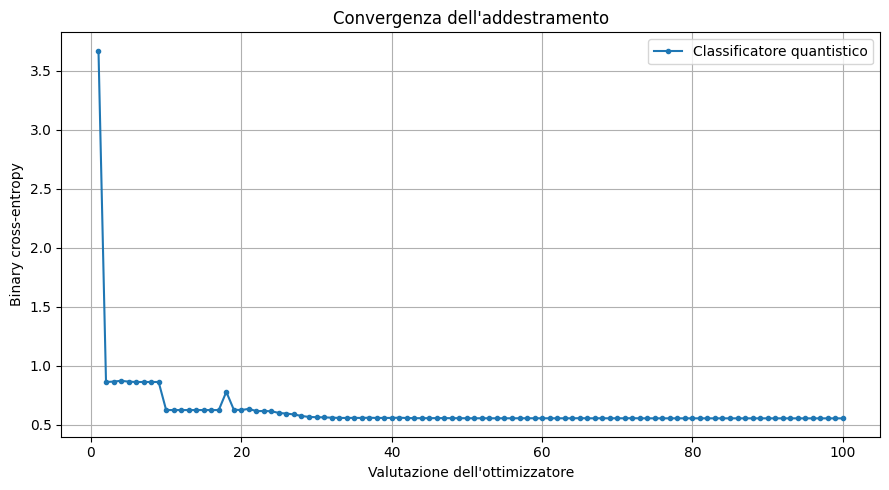

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    range(1, len(cost_history["cost_history"]) + 1),
    cost_history["cost_history"],
    "o-",
    markersize=3,
    label="Classificatore quantistico"
)
ax.set_xlabel("Valutazione dell'ottimizzatore")
ax.set_ylabel("Binary cross-entropy")
ax.set_title("Convergenza dell'addestramento")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Testiamo il classificatore

Calcoliamo le probabilità sulle galassie del test set, le convertiamo in etichette usando la soglia 0.5 e stampiamo accuratezza e report di classificazione. Mostriamo inoltre la matrice di confusione.

Accuratezza sul test set: 0.680 (68.0%)

                  precision    recall  f1-score   support

Ellittica/smooth       0.70      0.64      0.67        25
    Spirale/disk       0.67      0.72      0.69        25

        accuracy                           0.68        50
       macro avg       0.68      0.68      0.68        50
    weighted avg       0.68      0.68      0.68        50



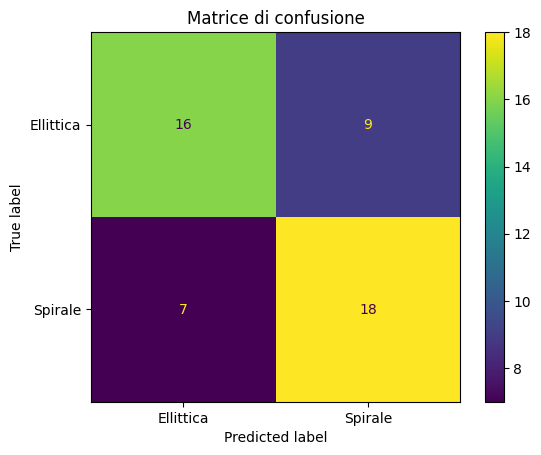

In [ ]:
test_probabilities = np.array([
    probability_spiral(x, trained_theta) for x in X_test
])
y_pred = (test_probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuratezza sul test set: {accuracy:.3f} ({accuracy * 100:.1f}%)")
print()
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ellittica/smooth", "Spirale/disk"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Ellittica", "Spirale"]
)
plt.title("Matrice di confusione")
plt.show()

## 10. Eseguiamo una galassia con la funzione `run`

Costruiamo il circuito per una galassia del test set, lo eseguiamo con la funzione `run` definita sopra e visualizziamo i conteggi delle misurazioni con un istogramma.

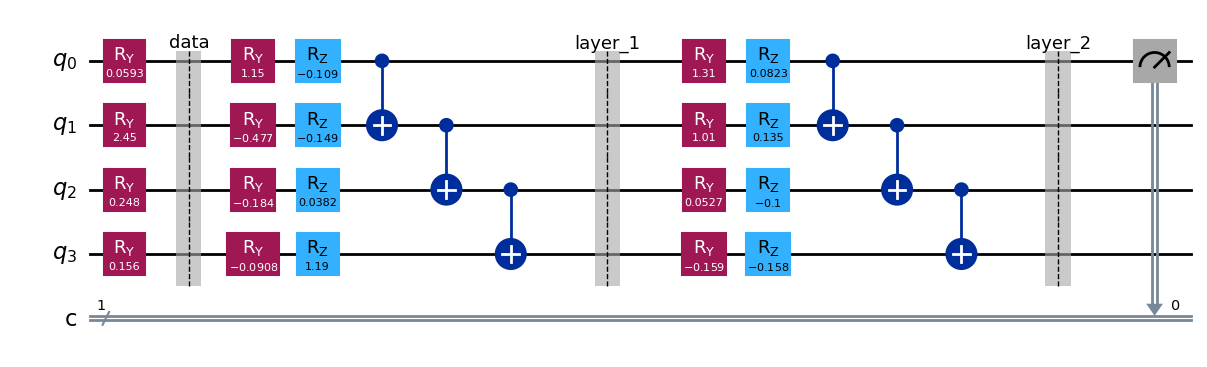

Etichetta reale: Spirale/disk
Probabilità spirale (Statevector): 0.861
Conteggi delle misurazioni: {'0': 279, '1': 1769}


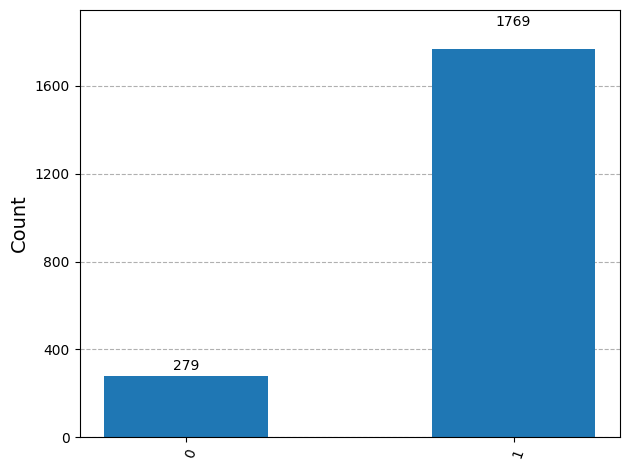

In [ ]:
example_index = 0
qc_measured = galaxy_circuit(
    X_test[example_index],
    trained_theta,
    measure=True
)

display(qc_measured.draw("mpl"))

counts = run(qc_measured, shots=2048)
print("Etichetta reale:", "Spirale/disk" if y_test[example_index] == 1 else "Ellittica/smooth")
print("Probabilità spirale (Statevector):", round(test_probabilities[example_index], 3))
print("Conteggi delle misurazioni:", counts)
plot_histogram(counts)

## 11. Proviamo una galassia e interpretiamo il risultato

Definiamo una funzione che prende una riga del dataset, calcola la probabilità che appartenga alla classe spirale e stampa la classe prevista. La prova viene eseguita sulla n galassia del dataset.

In [ ]:
n = 0

def classify_galaxy(row):
    x = row[features].to_numpy(dtype=float)
    p_spiral = probability_spiral(x, trained_theta)
    predicted_label = int(p_spiral >= 0.5)
    predicted_name = "Spirale/disk" if predicted_label == 1 else "Ellittica/smooth"

    real_name = row["class_name"]
    print("Classe reale:", real_name)
    print("\n")
    print(f"Probabilità spirale: {p_spiral:.3f}")
    print("Classe prevista:", predicted_name)
    return predicted_label

# Esempio: prima galassia del dataset
classify_galaxy(df.iloc[n])

Classe reale: ellittica_smooth


Probabilità spirale: 0.247
Classe prevista: Ellittica/smooth


0